# Лабораторная работа 1. Линейная регрессия — предсказание RiskScore
## Задание 1. Разведочный анализ данных (EDA)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = "."

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (11017, 35) | test: (5000, 35)


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,0.151985,2.0,1.0,0.168542,0.0,Education,0.0,23.0,5.0,2539.0,247.0,50072.0,15005.0,5569.083333,0.908289,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,0.175693,3.0,0.0,0.141553,0.0,Home,0.0,27.0,11.0,844.0,694.0,91878.0,64877.0,14345.583333,0.797339,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,0.444605,3.0,0.0,0.030987,1.0,Education,0.0,21.0,12.0,12756.0,651.0,292300.0,13918.0,25000.000000,0.915945,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,0.188452,7.0,0.0,0.379843,0.0,Debt Consolidation,0.0,27.0,21.0,1524.0,529.0,13070.0,3846.0,2890.250000,0.876416,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,0.273431,3.0,1.0,0.068659,0.0,Debt Consolidation,0.0,35.0,9.0,1973.0,128.0,33357.0,351603.0,25000.000000,0.888689,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091


## 1. Общая информация и пропуски

In [2]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 11017 entries, 0 to 11016
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             10487 non-null  str    
 1   Age                         10487 non-null  float64
 2   AnnualIncome                10487 non-null  float64
 3   CreditScore                 9986 non-null   float64
 4   LoanAmount                  9986 non-null   float64
 5   LoanDuration                10487 non-null  float64
 6   MaritalStatus               10487 non-null  str    
 7   NumberOfDependents          10487 non-null  float64
 8   HomeOwnershipStatus         10487 non-null  str    
 9   MonthlyDebtPayments         9986 non-null   float64
 10  CreditCardUtilizationRate   10487 non-null  float64
 11  NumberOfOpenCreditLines     10487 non-null  float64
 12  NumberOfCreditInquiries     10487 non-null  float64
 13  DebtToIncomeRatio           10487 non-null

In [3]:
miss = train.isna().sum()
print("Полностью пустых строк в train:", train.isna().all(axis=1).sum())
print("Распределение числа пропусков по строкам:")
print(train.isna().sum(axis=1).value_counts().sort_index())
print("\nПропуски по столбцам:")
print(miss[miss > 0])
print("\nПропусков в test:", test.isna().sum().sum())

Полностью пустых строк в train: 530
Распределение числа пропусков по строкам:
0     9986
9      501
35     530
Name: count, dtype: int64

Пропуски по столбцам:
ApplicationDate                530
Age                            530
AnnualIncome                   530
CreditScore                   1031
LoanAmount                    1031
LoanDuration                   530
MaritalStatus                  530
NumberOfDependents             530
HomeOwnershipStatus            530
MonthlyDebtPayments           1031
CreditCardUtilizationRate      530
NumberOfOpenCreditLines        530
NumberOfCreditInquiries        530
DebtToIncomeRatio              530
BankruptcyHistory             1031
LoanPurpose                   1031
PreviousLoanDefaults           530
PaymentHistory                 530
LengthOfCreditHistory          530
SavingsAccountBalance          530
CheckingAccountBalance        1031
TotalAssets                   1031
TotalLiabilities               530
MonthlyIncome                  530


В train есть 530 полностью пустых строк (их нечем использовать для обучения) и ещё
~500 строк, где пропущена одна и та же группа из 9 признаков.
В test пропусков нет.

In [4]:

df = train.dropna(how="all").reset_index(drop=True)
print("После удаления пустых строк:", df.shape)

После удаления пустых строк: (10487, 35)


## 2. Целевая переменная RiskScore

In [5]:
print(df["RiskScore"].describe())
anom = df["RiskScore"].abs() >= 1e6
print("\nАномальных значений (|RiskScore| >= 1e6):", anom.sum())
print(df.loc[anom, "RiskScore"].value_counts())

count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64

Аномальных значений (|RiskScore| >= 1e6): 215
RiskScore
-9999999.0     121
 10000000.0     94
Name: count, dtype: int64


После удаления аномалий целевой переменной: (10272, 35)
count    10272.000000
mean        48.358094
std         17.241456
min         14.841417
25%         32.722756
50%         44.195792
75%         65.124190
max         97.597249
Name: RiskScore, dtype: float64
Асимметрия: 0.329


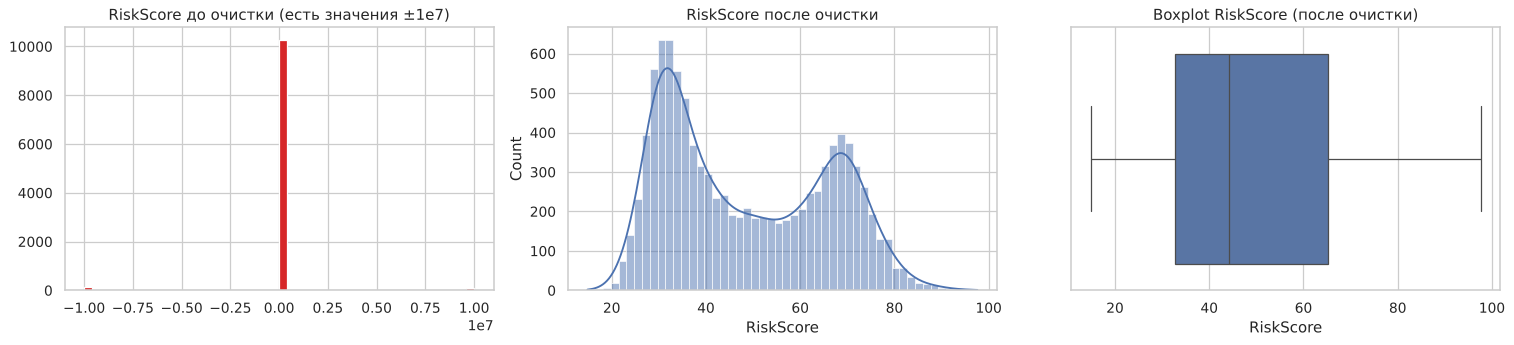

In [6]:
clean = df.loc[~anom].reset_index(drop=True)
print("После удаления аномалий целевой переменной:", clean.shape)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(df["RiskScore"], bins=50, color="tab:red")
ax[0].set_title("RiskScore до очистки (есть значения ±1e7)")
sns.histplot(clean["RiskScore"], bins=50, kde=True, ax=ax[1])
ax[1].set_title("RiskScore после очистки")
sns.boxplot(x=clean["RiskScore"], ax=ax[2])
ax[2].set_title("Boxplot RiskScore (после очистки)")
plt.tight_layout(); plt.show()
print(clean["RiskScore"].describe())
print("Асимметрия:", round(clean["RiskScore"].skew(), 3))

Значения ±9 999 999 / ±10 000 000 — явные «маркеры» ошибок/выбросов, а не реальный риск
(реальный диапазон ≈ 15–98). Они искажают MSE на порядки, поэтому удаляются из обучающей выборки.

## 3. Признаки
Дату заявки разбираем на год и месяц, остальные столбцы делим на числовые и категориальные.

In [7]:
clean["ApplicationDate"] = pd.to_datetime(clean["ApplicationDate"])
clean["Year"] = clean["ApplicationDate"].dt.year
clean["Month"] = clean["ApplicationDate"].dt.month

cat_cols = ["MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "EmploymentStatus", "EducationLevel"]
target = "RiskScore"
num_cols = [c for c in clean.select_dtypes("number").columns if c != target]
print("Числовых признаков:", len(num_cols), "| категориальных:", len(cat_cols))
clean[num_cols].describe().T

Числовых признаков: 30 | категориальных: 5


,count,mean,std,min,25%,50%,75%,max
Age,10272.0,39.862344,11.604454,18.000000,32.000000,40.000000,48.000000,8.000000e+01
AnnualIncome,10272.0,131532.945483,115827.564691,15000.000000,20891.000000,88994.500000,257225.000000,7.485080e+05
CreditScore,9787.0,677.911515,175.374136,300.000000,550.000000,722.000000,850.000000,8.500000e+02
LoanAmount,9787.0,29925.122509,27812.837524,1063.000000,12656.000000,21836.000000,37289.500000,4.189970e+05
LoanDuration,10272.0,53.425234,24.521956,12.000000,36.000000,48.000000,60.000000,1.200000e+02
NumberOfDependents,10272.0,1.567854,1.417676,0.000000,0.000000,1.000000,3.000000,6.000000e+00
MonthlyDebtPayments,9787.0,546.437928,502.599753,13.000000,233.000000,398.000000,683.500000,1.087900e+04
CreditCardUtilizationRate,10272.0,0.284565,0.159417,0.003674,0.159118,0.262313,0.391387,9.146347e-01
NumberOfOpenCreditLines,10272.0,3.029108,1.738651,0.000000,2.000000,3.000000,4.000000,1.200000e+01
NumberOfCreditInquiries,10272.0,0.977998,0.988643,0.000000,0.000000,1.000000,2.000000,6.000000e+00


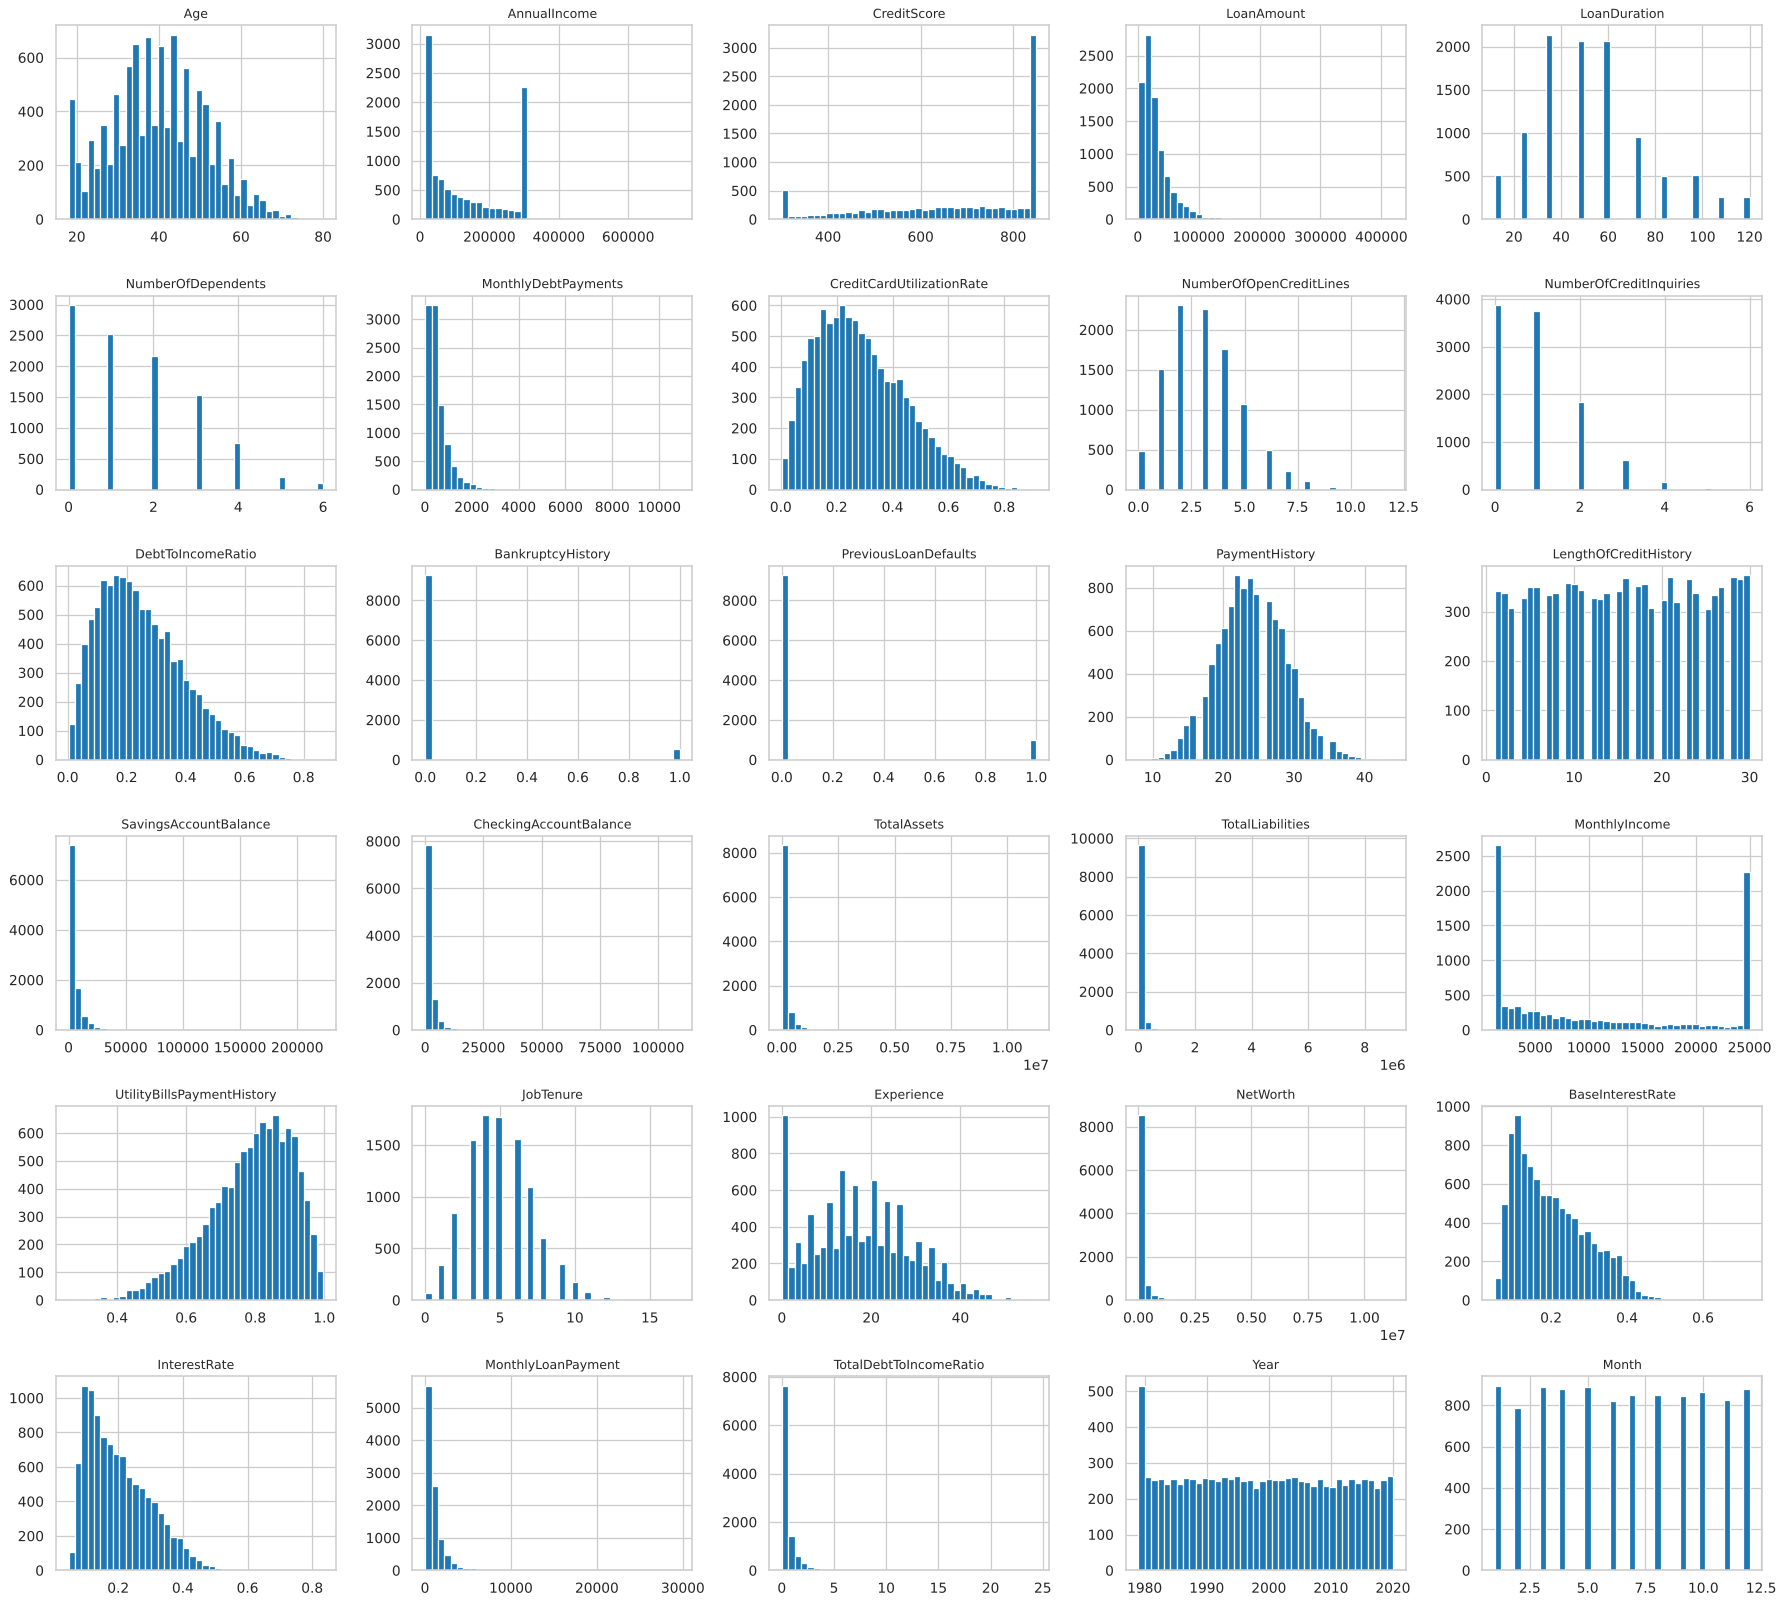

In [8]:

n = len(num_cols)
cols = 5
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(20, 3 * rows))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(clean[c].dropna(), bins=40, color="tab:blue")
    ax.set_title(c, fontsize=10)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [9]:
skew = clean[num_cols].skew().sort_values(ascending=False)
print("Наиболее скошенные признаки (тяжёлые правые хвосты):")
print(skew.head(8).round(2))

Наиболее скошенные признаки (тяжёлые правые хвосты):
TotalLiabilities          18.16
NetWorth                  10.72
TotalAssets               10.39
CheckingAccountBalance     9.01
TotalDebtToIncomeRatio     7.12
SavingsAccountBalance      6.67
MonthlyLoanPayment         5.77
BankruptcyHistory          4.01
dtype: float64


## 4. Корреляционная матрица

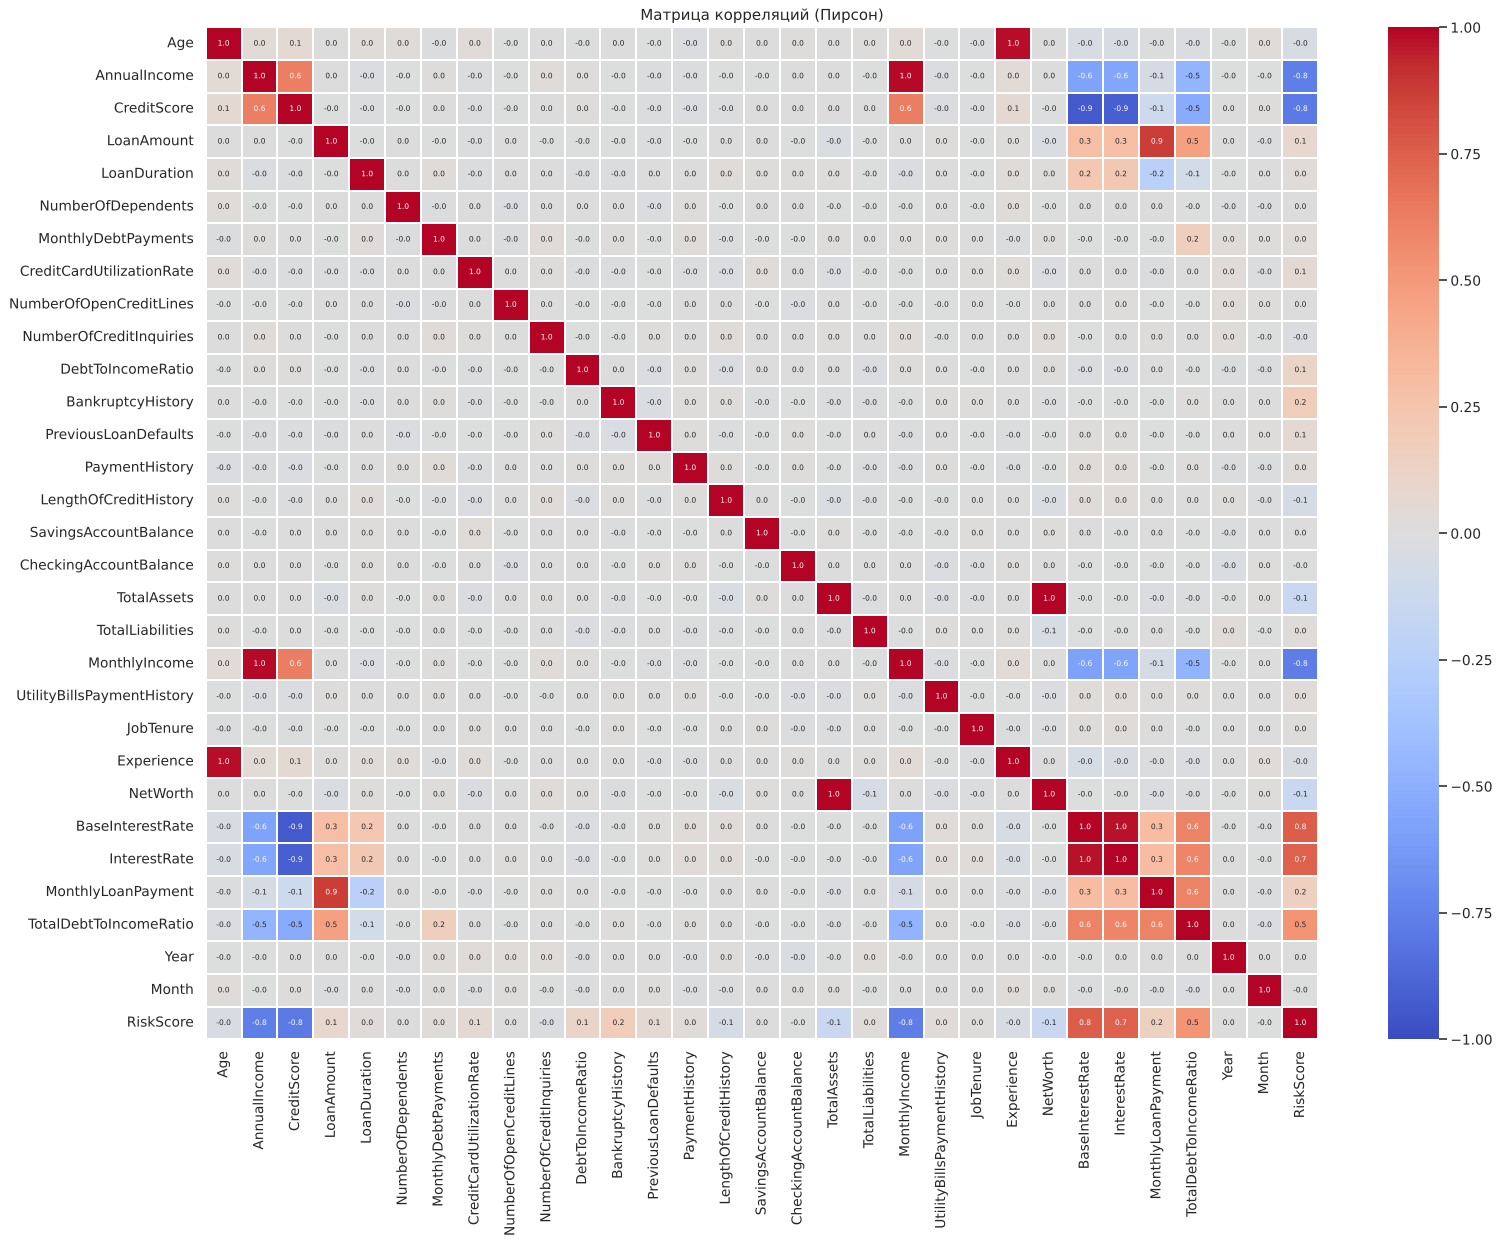

In [10]:
corr = clean[num_cols + [target]].corr()
plt.figure(figsize=(18, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 6}, linewidths=0.2)
plt.title("Матрица корреляций (Пирсон)")
plt.tight_layout(); plt.show()

Корреляция признаков с RiskScore:
CreditScore                 -0.785
MonthlyIncome               -0.770
BaseInterestRate             0.759
AnnualIncome                -0.759
InterestRate                 0.743
TotalDebtToIncomeRatio       0.531
BankruptcyHistory            0.178
MonthlyLoanPayment           0.151
TotalAssets                 -0.146
NetWorth                    -0.145
DebtToIncomeRatio            0.111
LoanAmount                   0.085
LengthOfCreditHistory       -0.061
CreditCardUtilizationRate    0.056
PreviousLoanDefaults         0.055
Name: RiskScore, dtype: float64


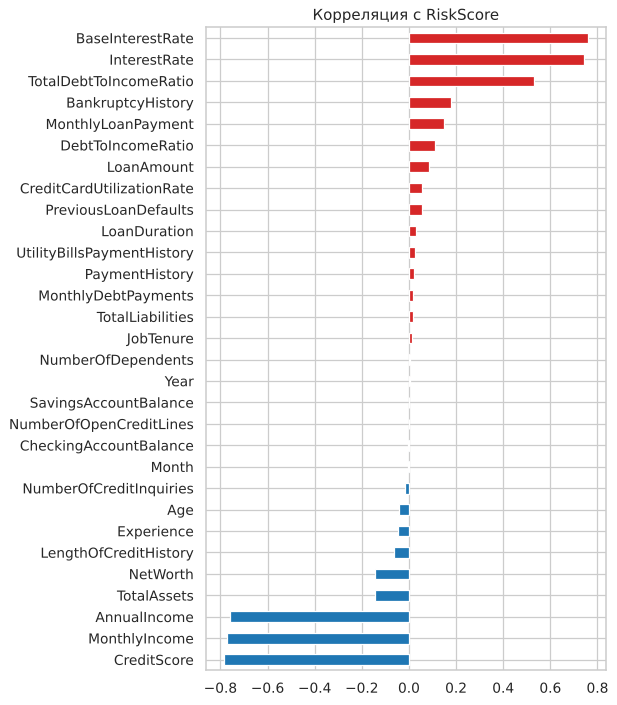

In [11]:
corr_target = corr[target].drop(target).sort_values(key=np.abs, ascending=False)
print("Корреляция признаков с RiskScore:")
print(corr_target.head(15).round(3))

plt.figure(figsize=(7, 8))
corr_target.sort_values().plot.barh(color=np.where(corr_target.sort_values() > 0, "tab:red", "tab:blue"))
plt.title("Корреляция с RiskScore"); plt.tight_layout(); plt.show()

In [12]:

c_abs = corr.drop(index=target, columns=target).abs()
pairs = (c_abs.where(np.triu(np.ones(c_abs.shape), k=1).astype(bool))
              .stack().sort_values(ascending=False))
print("Пары признаков с |corr| > 0.85:")
print(pairs[pairs > 0.85].round(3))

Пары признаков с |corr| > 0.85:
TotalAssets       NetWorth              0.994
AnnualIncome      MonthlyIncome         0.985
Age               Experience            0.983
BaseInterestRate  InterestRate          0.975
CreditScore       BaseInterestRate      0.932
                  InterestRate          0.907
LoanAmount        MonthlyLoanPayment    0.873
dtype: float64


## 5. Графики зависимостей признаков друг от друга и от целевой переменной

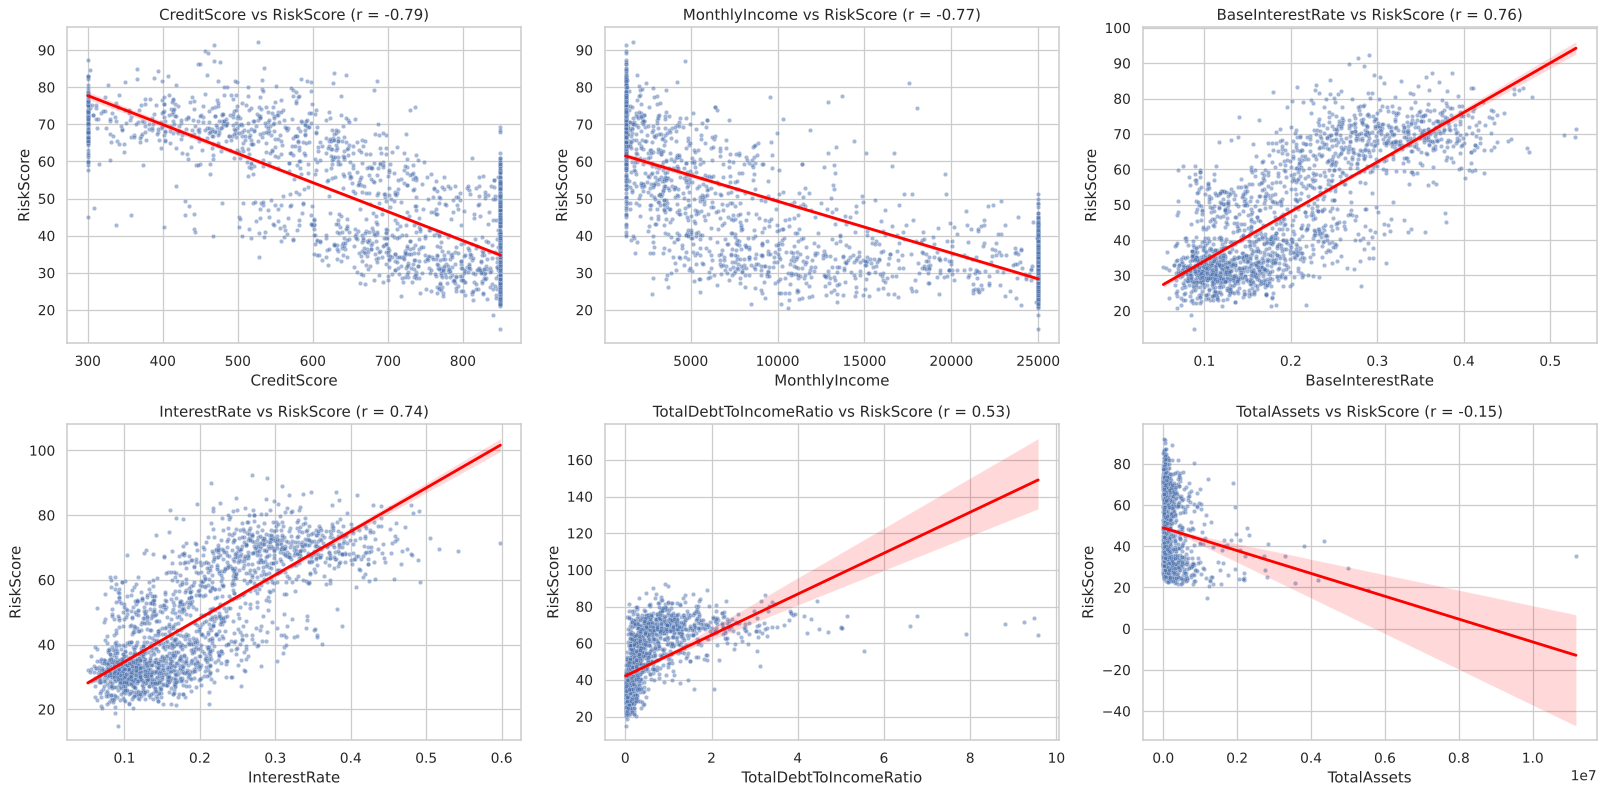

In [13]:

top = ["CreditScore", "MonthlyIncome", "BaseInterestRate", "InterestRate", "TotalDebtToIncomeRatio", "TotalAssets"]
sample = clean.sample(2000, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), top):
    sns.scatterplot(data=sample, x=c, y=target, s=12, alpha=0.5, ax=ax)
    sns.regplot(data=sample, x=c, y=target, scatter=False, color="red", ax=ax)
    ax.set_title(f"{c} vs RiskScore (r = {corr.loc[c, target]:.2f})")
plt.tight_layout(); plt.show()

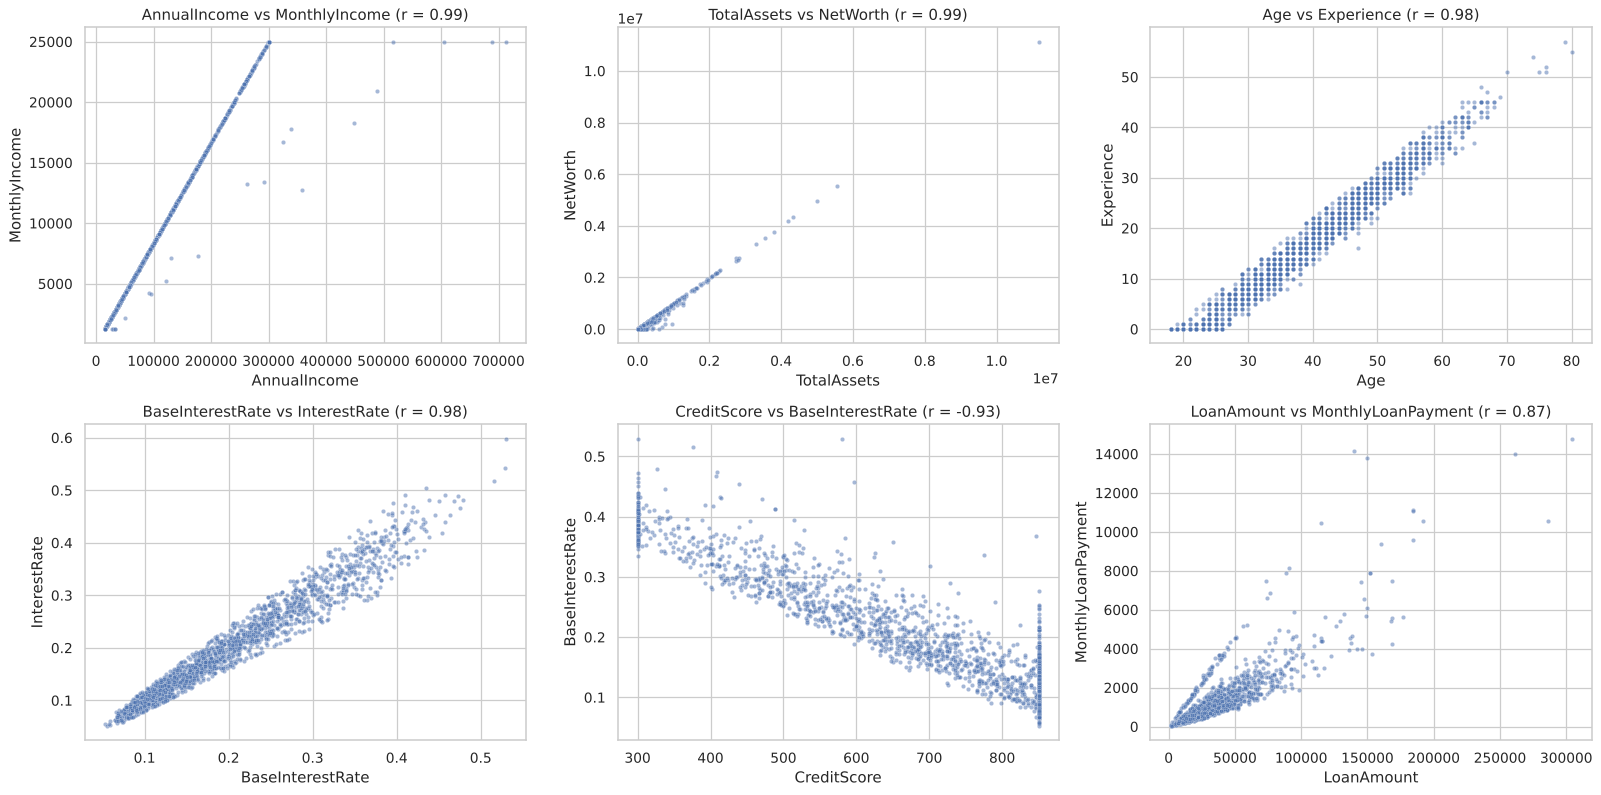

In [14]:

pairs_plot = [("AnnualIncome", "MonthlyIncome"), ("TotalAssets", "NetWorth"), ("Age", "Experience"),
              ("BaseInterestRate", "InterestRate"), ("CreditScore", "BaseInterestRate"),
              ("LoanAmount", "MonthlyLoanPayment")]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (a, b) in zip(axes.ravel(), pairs_plot):
    sns.scatterplot(data=sample, x=a, y=b, s=12, alpha=0.5, ax=ax)
    ax.set_title(f"{a} vs {b} (r = {corr.loc[a, b]:.2f})")
plt.tight_layout(); plt.show()

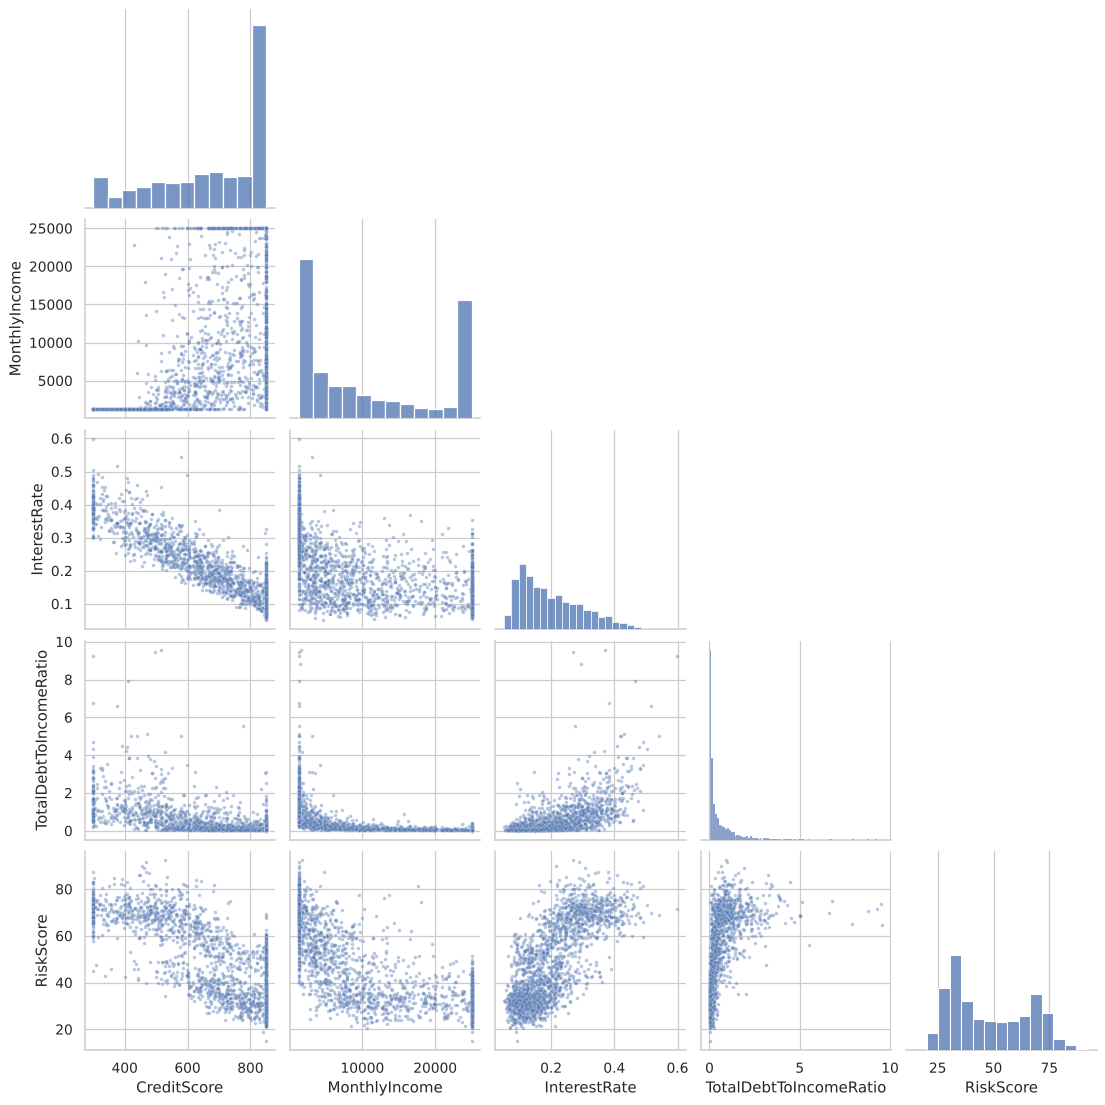

In [15]:

sns.pairplot(sample[["CreditScore", "MonthlyIncome", "InterestRate", "TotalDebtToIncomeRatio", target]],
             corner=True, plot_kws={"s": 8, "alpha": 0.4})
plt.show()

## 6. Категориальные признаки и дата

EmploymentStatus
Employed         48.01
Self-Employed    50.17
Unemployed       51.58
Name: RiskScore, dtype: float64


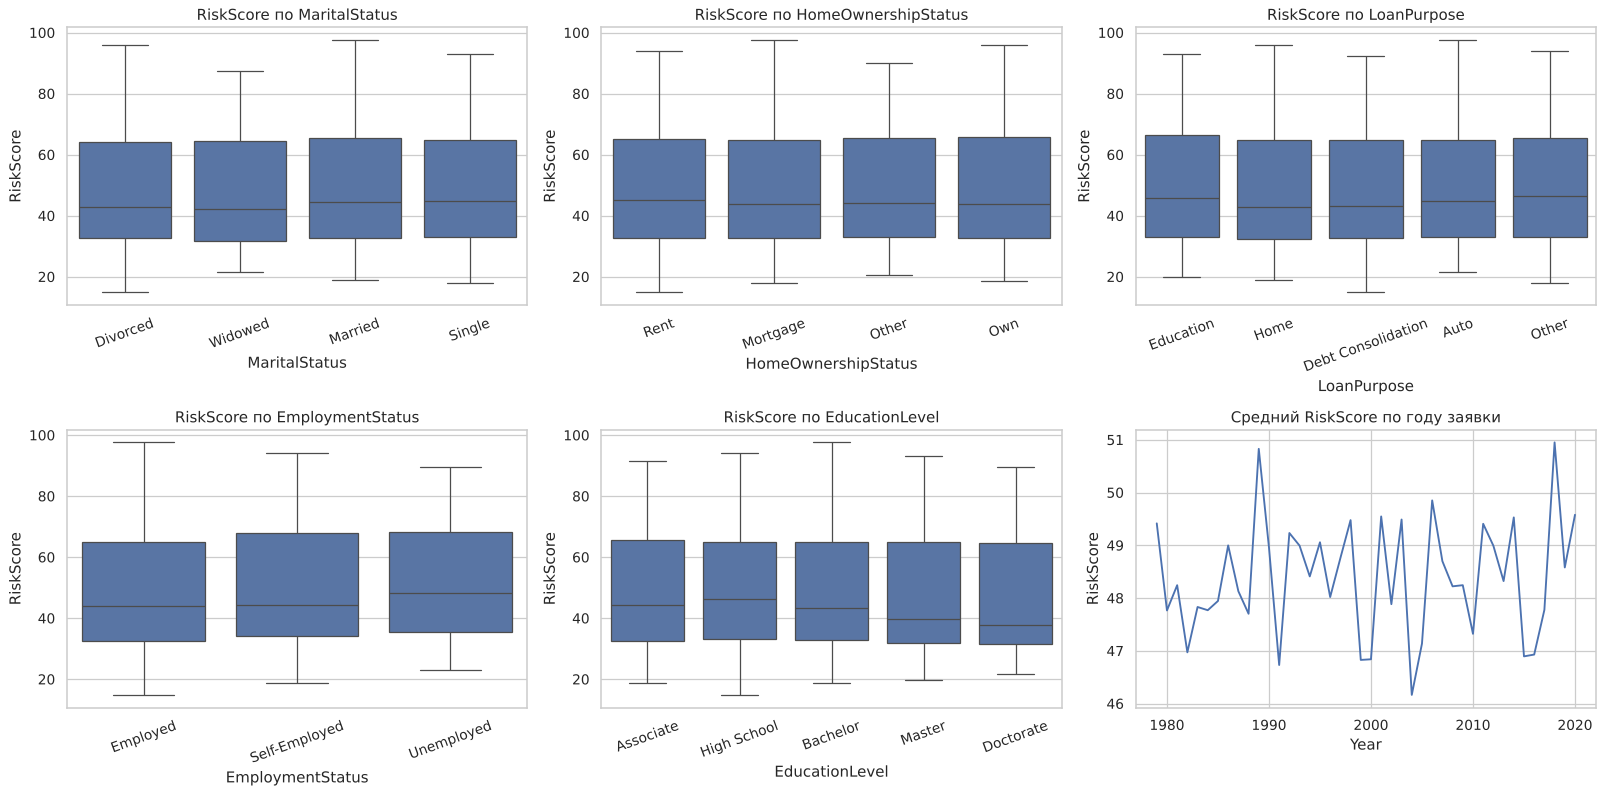

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.boxplot(data=clean, x=c, y=target, ax=ax)
    ax.set_title(f"RiskScore по {c}")
    ax.tick_params(axis="x", rotation=20)
sns.lineplot(data=clean.groupby("Year")[target].mean().reset_index(), x="Year", y=target, ax=axes[1, 2])
axes[1, 2].set_title("Средний RiskScore по году заявки")
plt.tight_layout(); plt.show()

print(clean.groupby("EmploymentStatus")[target].mean().round(2))

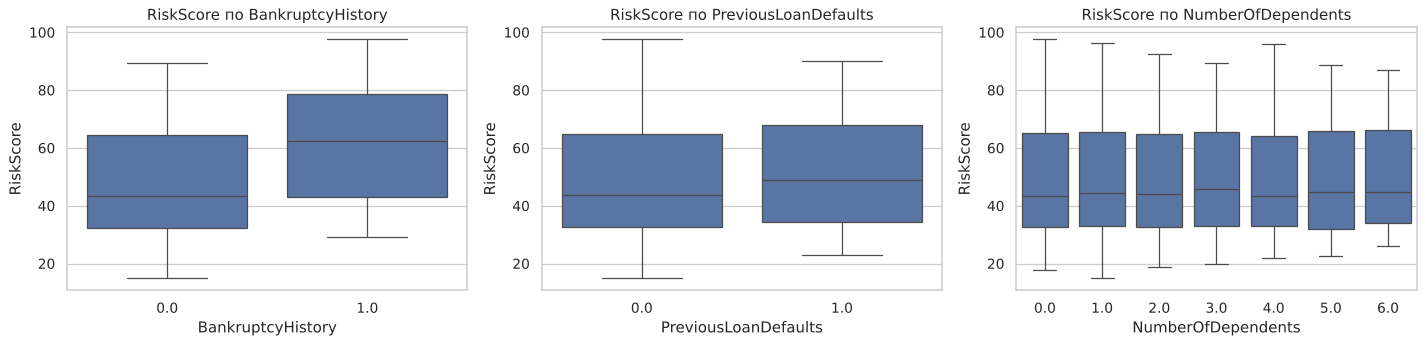

In [17]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["BankruptcyHistory", "PreviousLoanDefaults", "NumberOfDependents"]):
    sns.boxplot(data=clean, x=c, y=target, ax=ax)
    ax.set_title(f"RiskScore по {c}")
plt.tight_layout(); plt.show()

## 7. Выводы по EDA

1. **Качество данных.** В train 530 полностью пустых строк и ещё ~500 строк с пропуском одной и той же группы
   из 9 признаков (CreditScore, LoanAmount, MonthlyDebtPayments, BankruptcyHistory, LoanPurpose,
   CheckingAccountBalance, TotalAssets, NetWorth, BaseInterestRate). В test пропусков нет.
2. **Целевая переменная.** В RiskScore есть 215 аномальных значений (±9 999 999 и ±10 000 000), которые
   не являются реальным риском. После их удаления RiskScore лежит в диапазоне ≈ 15–98, среднее ≈ 48,
   асимметрия небольшая (≈ 0.3). Распределение двугорбое: есть группа с низким риском (≈ 30) и с высоким (≈ 70).
3. **Главные предикторы** (линейная корреляция с RiskScore): CreditScore (−0.79), MonthlyIncome (−0.77),
   AnnualIncome (−0.76), BaseInterestRate (+0.76), InterestRate (+0.74), TotalDebtToIncomeRatio (+0.53).
   Остальные признаки (возраст, образование, семейное положение, цель кредита, год заявки и т. д.) почти не
   связаны с целевой переменной.
4. **Мультиколлинеарность.** Есть почти дублирующие друг друга пары: TotalAssets–NetWorth (0.99),
   AnnualIncome–MonthlyIncome (0.99), Age–Experience (0.98), BaseInterestRate–InterestRate (0.98),
   CreditScore–BaseInterestRate (0.93), LoanAmount–MonthlyLoanPayment (0.87). Для линейной регрессии это
   значит, что аналитическое решение может быть плохо обусловлено, а коэффициенты неустойчивы;
   поможет регуляризация (L1/L2) или удаление дублирующих признаков.
5. **Тяжёлые хвосты и «обрезка» значений.** TotalLiabilities, NetWorth, TotalAssets, TotalDebtToIncomeRatio,
   MonthlyLoanPayment и остатки на счетах имеют сильную правую асимметрию с выбросами. CreditScore ограничен
   сверху значением 850, а MonthlyIncome «прижат» к границам 1250 и 25000 (много наблюдений ровно на границах).
   Поэтому масштабирование (z-score / min-max) обязательно, особенно для градиентного спуска.
6. **Вид зависимостей.** Зависимости главных признаков от RiskScore в целом убывающие/возрастающие, но
   облако точек состоит из двух кластеров (низкий и высокий риск), так что чистая линейная связь описывает
   их лишь частично. Это нужно учитывать при оценке достижимого MSE.
7. **Категориальные признаки** влияют слабо: самые заметные различия по EmploymentStatus (безработные ≈ 51.6,
   занятые ≈ 48.0) и EducationLevel (Doctorate ≈ 46.1 против High School ≈ 49.0). Кодировать их стоит
   one-hot, они дают небольшую добавку.
8. **Дата заявки** (год, месяц) не показывает выраженной связи с риском.